<center><h1>Customer Segmentation</h1></center>

In [9]:
# Configure Thread Limit to Avoid K-Means Memory Warning
import os
os.environ["OMP_NUM_THREADS"] = "2"

print("OMP_NUM_THREADS:", os.environ["OMP_NUM_THREADS"])

OMP_NUM_THREADS: 2


In [12]:
import pandas as pd

df_customers = pd.read_csv(
    "../data/raw/customer_transactions.csv"
)

print("Dataset Shape:", df_customers.shape)
print("\nColumns:")
print(df_customers.columns.tolist())

df_customers.head()

Dataset Shape: (71661, 9)

Columns:
['Transaction_ID', 'Transaction_Date', 'Customer_ID', 'SKU', 'Quantity', 'Unit_Price', 'Revenue', 'Country', 'Promotion']


,Transaction_ID,Transaction_Date,Customer_ID,SKU,Quantity,Unit_Price,Revenue,Country,Promotion
0,TXN0000001,2024-01-01,CUST0387,SKU001,5,3664.05,18320.25,India,0
1,TXN0000002,2024-01-01,CUST0220,SKU002,9,3805.69,34251.21,India,0
2,TXN0000003,2024-01-01,CUST0043,SKU002,6,3805.69,22834.14,India,0
3,TXN0000004,2024-01-01,CUST0048,SKU003,5,8078.23,40391.15,India,0
4,TXN0000005,2024-01-01,CUST0487,SKU004,3,6861.57,20584.71,India,0


In [14]:
# Check data types and data quality
print("Data Types:")
print(df_customers.dtypes)

print("\nMissing Values:")
print(df_customers.isnull().sum())

print("\nDuplicate Transaction IDs:",
      df_customers["Transaction_ID"].duplicated().sum())

print("\nUnique Customers:",
      df_customers["Customer_ID"].nunique())

print("\nTransaction Date Range:",
      df_customers["Transaction_Date"].min(),
      "to",
      df_customers["Transaction_Date"].max())

Data Types:
Transaction_ID       object
Transaction_Date     object
Customer_ID          object
SKU                  object
Quantity              int64
Unit_Price          float64
Revenue             float64
Country              object
Promotion             int64
dtype: object

Missing Values:
Transaction_ID      0
Transaction_Date    0
Customer_ID         0
SKU                 0
Quantity            0
Unit_Price          0
Revenue             0
Country             0
Promotion           0
dtype: int64

Duplicate Transaction IDs: 0

Unique Customers: 500

Transaction Date Range: 2024-01-01 to 2025-12-31


In [16]:
# Customer-level RFM table banao

# Prepare transaction dates
df_customers["Transaction_Date"] = pd.to_datetime(
    df_customers["Transaction_Date"]
)

# Set analysis date as the day after the last transaction
analysis_date = df_customers["Transaction_Date"].max() + pd.Timedelta(days=1)

# Calculate RFM metrics for each customer
rfm = df_customers.groupby("Customer_ID").agg(
    Recency=("Transaction_Date", lambda x: (analysis_date - x.max()).days),
    Frequency=("Transaction_ID", "nunique"),
    Monetary=("Revenue", "sum")
).reset_index()

print("RFM Dataset Shape:", rfm.shape)
rfm.head()

RFM Dataset Shape: (500, 4)


,Customer_ID,Recency,Frequency,Monetary
0,CUST0001,7,158,7260833.34
1,CUST0002,7,142,5836030.15
2,CUST0003,12,157,6882724.14
3,CUST0004,8,151,5680435.41
4,CUST0005,3,121,4692442.97


In [18]:
# Summarize customer RFM metrics
rfm[["Recency", "Frequency", "Monetary"]].describe().round(2)

,Recency,Frequency,Monetary
count,500.00,500.00,500.00
mean,5.50,143.32,6192113.41
std,4.63,11.68,756542.95
min,1.00,112.00,4008251.30
25%,2.00,136.00,5705121.82
50%,4.00,143.00,6154592.86
75%,8.00,150.00,6649511.96
max,33.00,176.00,8628535.28


In [20]:

from sklearn.preprocessing import StandardScaler

# Select RFM features
rfm_features = rfm[["Recency", "Frequency", "Monetary"]]

# Scale the features
scaler = StandardScaler()
rfm_scaled = scaler.fit_transform(rfm_features)

print("Scaled RFM Shape:", rfm_scaled.shape)
print("\nFirst 5 scaled rows:")
print(rfm_scaled[:5].round(2))

Scaled RFM Shape: (500, 3)

First 5 scaled rows:
[[ 0.32  1.26  1.41]
 [ 0.32 -0.11 -0.47]
 [ 1.4   1.17  0.91]
 [ 0.54  0.66 -0.68]
 [-0.54 -1.91 -1.98]]


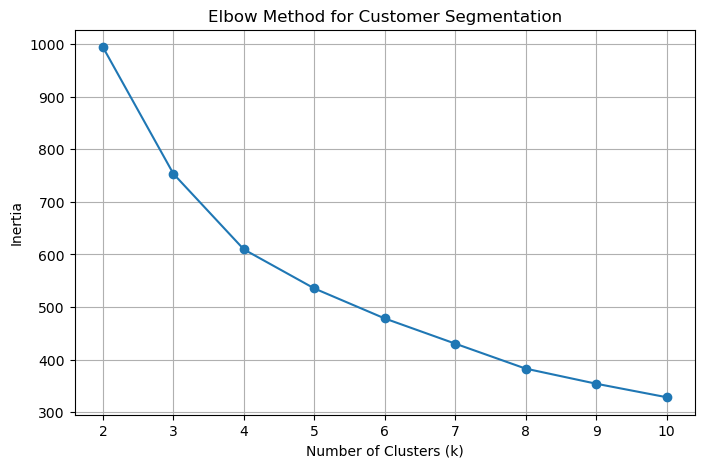

In [22]:
# Elbow Method
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans

# Calculate inertia for different cluster counts
inertia = []

for k in range(2, 11):
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    kmeans.fit(rfm_scaled)
    inertia.append(kmeans.inertia_)

# Plot the Elbow curve
plt.figure(figsize=(8, 5))
plt.plot(range(2, 11), inertia, marker="o")
plt.xlabel("Number of Clusters (k)")
plt.ylabel("Inertia")
plt.title("Elbow Method for Customer Segmentation")
plt.xticks(range(2, 11))
plt.grid(True)
plt.show()

In [24]:
# Display Inertia Values for Cluster Selection
elbow_results = pd.DataFrame({
    "Number_of_Clusters": range(2, 11),
    "Inertia": inertia
})

print(elbow_results.round(2).to_string(index=False))

 Number_of_Clusters  Inertia
                  2   994.03
                  3   753.33
                  4   609.58
                  5   535.35
                  6   478.27
                  7   430.40
                  8   382.88
                  9   354.20
                 10   328.52


In [26]:
# Apply K-Means Customer Segmentation
from sklearn.cluster import KMeans

kmeans = KMeans(
    n_clusters=4,
    random_state=42,
    n_init=10
)

rfm["Cluster"] = kmeans.fit_predict(rfm_scaled)

print("Customer Segmentation Completed")
print("\nCustomers per Cluster:")
print(rfm["Cluster"].value_counts().sort_index())

Customer Segmentation Completed

Customers per Cluster:
Cluster
0    185
1    137
2     92
3     86
Name: count, dtype: int64


In [28]:
# Analyze RFM Metrics by Customer Cluster
cluster_summary = rfm.groupby("Cluster").agg(
    Customer_Count=("Customer_ID", "count"),
    Avg_Recency=("Recency", "mean"),
    Avg_Frequency=("Frequency", "mean"),
    Avg_Monetary=("Monetary", "mean")
).round(2)

print(cluster_summary)

         Customer_Count  Avg_Recency  Avg_Frequency  Avg_Monetary
Cluster                                                          
0                   185         3.23         143.60    6276296.04
1                   137         4.48         131.44    5384576.54
2                    92         4.65         158.37    7181855.91
3                    86        12.92         145.56    6238653.61


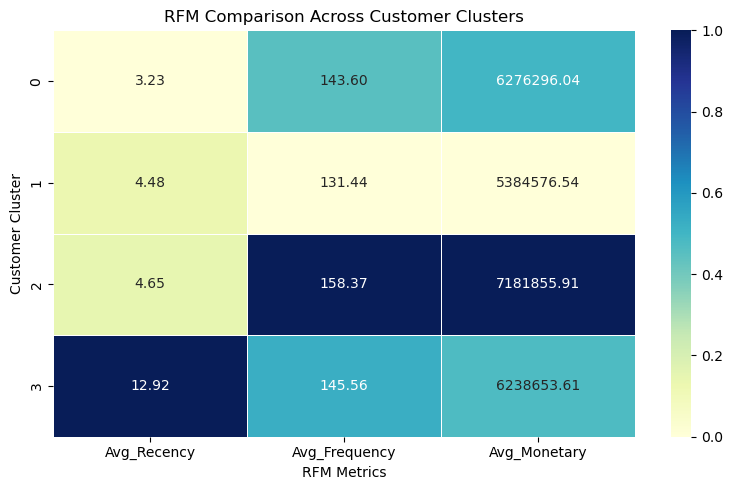

In [30]:
# Visualize RFM Metrics Across Customer Clusters
import seaborn as sns
import matplotlib.pyplot as plt

heatmap_data = cluster_summary[
    ["Avg_Recency", "Avg_Frequency", "Avg_Monetary"]
].copy()

# Normalize metrics so different scales can be compared
heatmap_scaled = (
    heatmap_data - heatmap_data.min()
) / (
    heatmap_data.max() - heatmap_data.min()
)

plt.figure(figsize=(8, 5))
sns.heatmap(
    heatmap_scaled,
    annot=heatmap_data,
    fmt=".2f",
    cmap="YlGnBu",
    linewidths=0.5
)
plt.title("RFM Comparison Across Customer Clusters")
plt.xlabel("RFM Metrics")
plt.ylabel("Customer Cluster")
plt.tight_layout()
plt.show()

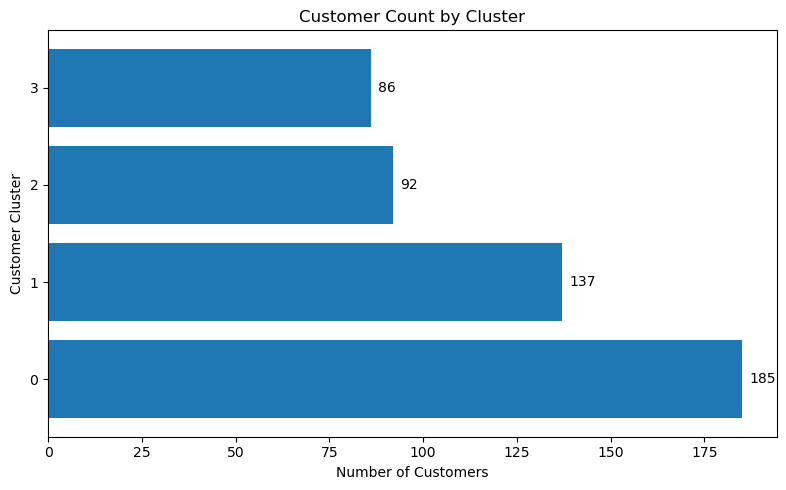

In [32]:
# Compare Customer Count Across Clusters
import matplotlib.pyplot as plt

cluster_counts = rfm["Cluster"].value_counts().sort_index()

plt.figure(figsize=(8, 5))
plt.barh(
    cluster_counts.index.astype(str),
    cluster_counts.values
)

plt.title("Customer Count by Cluster")
plt.xlabel("Number of Customers")
plt.ylabel("Customer Cluster")

for i, value in enumerate(cluster_counts.values):
    plt.text(value + 2, i, str(value), va="center")

plt.tight_layout()
plt.show()

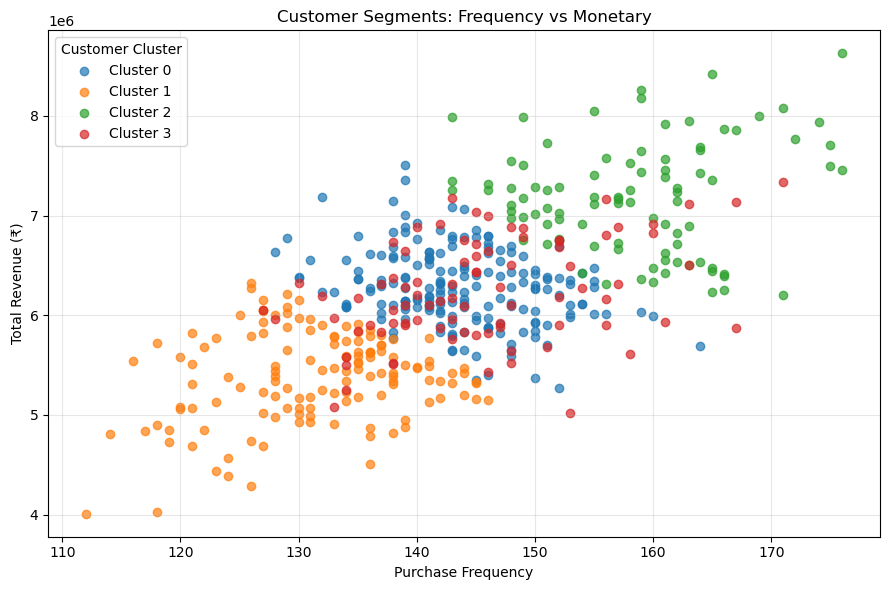

In [34]:
# Visualize Customer Clusters by Frequency and Monetary Value
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 6))

for cluster_id in sorted(rfm["Cluster"].unique()):
    cluster_data = rfm[rfm["Cluster"] == cluster_id]

    plt.scatter(
        cluster_data["Frequency"],
        cluster_data["Monetary"],
        label=f"Cluster {cluster_id}",
        alpha=0.7
    )

plt.title("Customer Segments: Frequency vs Monetary")
plt.xlabel("Purchase Frequency")
plt.ylabel("Total Revenue (₹)")
plt.legend(title="Customer Cluster")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [36]:
# Save Customer Segmentation Results
import os

output_path = "../data/processed/customer_segments.csv"

os.makedirs("../data/processed", exist_ok=True)

rfm.to_csv(output_path, index=False)

print("Customer segments saved successfully!")
print("File path:", output_path)
print("Dataset shape:", rfm.shape)

Customer segments saved successfully!
File path: ../data/processed/customer_segments.csv
Dataset shape: (500, 5)


In [38]:
# Create Business-Friendly Customer Cluster Profiles
cluster_profile = rfm.groupby("Cluster").agg(
    Customer_Count=("Customer_ID", "count"),
    Avg_Recency=("Recency", "mean"),
    Avg_Frequency=("Frequency", "mean"),
    Avg_Monetary=("Monetary", "mean")
).round(2)

cluster_profile["Customer_Percentage"] = (
    cluster_profile["Customer_Count"] / len(rfm) * 100
).round(2)

cluster_profile = cluster_profile.sort_values(
    "Avg_Monetary", ascending=False
)

print(cluster_profile)

         Customer_Count  Avg_Recency  Avg_Frequency  Avg_Monetary  \
Cluster                                                             
2                    92         4.65         158.37    7181855.91   
0                   185         3.23         143.60    6276296.04   
3                    86        12.92         145.56    6238653.61   
1                   137         4.48         131.44    5384576.54   

         Customer_Percentage  
Cluster                       
2                       18.4  
0                       37.0  
3                       17.2  
1                       27.4  


In [40]:
# Assign Business-Friendly Names to Customer Clusters
cluster_names = {
    0: "Recent Active Customers",
    1: "Lower Spending Customers",
    2: "High Value Frequent Customers",
    3: "Needs Re-engagement"
}

rfm["Segment_Name"] = rfm["Cluster"].map(cluster_names)

print(
    rfm[["Customer_ID", "Recency", "Frequency",
         "Monetary", "Cluster", "Segment_Name"]].head()
)

print("\nSegment Counts:")
print(rfm["Segment_Name"].value_counts())

  Customer_ID  Recency  Frequency    Monetary  Cluster  \
0    CUST0001        7        158  7260833.34        2   
1    CUST0002        7        142  5836030.15        0   
2    CUST0003       12        157  6882724.14        3   
3    CUST0004        8        151  5680435.41        3   
4    CUST0005        3        121  4692442.97        1   

                    Segment_Name  
0  High Value Frequent Customers  
1        Recent Active Customers  
2            Needs Re-engagement  
3            Needs Re-engagement  
4       Lower Spending Customers  

Segment Counts:
Segment_Name
Recent Active Customers          185
Lower Spending Customers         137
High Value Frequent Customers     92
Needs Re-engagement               86
Name: count, dtype: int64


In [42]:
# Update Customer Segmentation Output File
rfm.to_csv("../data/processed/customer_segments.csv", index=False)

print("Updated customer_segments.csv successfully!")
print("Rows:", len(rfm))
print("Columns:", rfm.columns.tolist())

Updated customer_segments.csv successfully!
Rows: 500
Columns: ['Customer_ID', 'Recency', 'Frequency', 'Monetary', 'Cluster', 'Segment_Name']


In [44]:
# Save Customer Cluster Summary
cluster_profile.to_csv(
    "../data/processed/customer_cluster_summary.csv"
)

print("Customer cluster summary saved successfully!")
print("File path: ../data/processed/customer_cluster_summary.csv")

Customer cluster summary saved successfully!
File path: ../data/processed/customer_cluster_summary.csv


In [46]:
# Verify Customer Segmentation Output Files
import os
import pandas as pd

customer_file = "../data/processed/customer_segments.csv"
summary_file = "../data/processed/customer_cluster_summary.csv"

print("Customer file exists:", os.path.exists(customer_file))
print("Summary file exists:", os.path.exists(summary_file))

df_segments_check = pd.read_csv(customer_file)
df_summary_check = pd.read_csv(summary_file)

print("\nCustomer file shape:", df_segments_check.shape)
print("Unique customers:", df_segments_check["Customer_ID"].nunique())
print("Missing values:", df_segments_check.isnull().sum().sum())

print("\nCluster summary shape:", df_summary_check.shape)
print("\nSegment distribution:")
print(df_segments_check["Segment_Name"].value_counts())

Customer file exists: True
Summary file exists: True

Customer file shape: (500, 6)
Unique customers: 500
Missing values: 0

Cluster summary shape: (4, 6)

Segment distribution:
Segment_Name
Recent Active Customers          185
Lower Spending Customers         137
High Value Frequent Customers     92
Needs Re-engagement               86
Name: count, dtype: int64


In [48]:

# Apply DBSCAN Customer Clustering

from sklearn.cluster import DBSCAN

dbscan = DBSCAN(
    eps=0.5,
    min_samples=5
)

rfm["DBSCAN_Cluster"] = dbscan.fit_predict(rfm_scaled)

print("DBSCAN Clustering Completed")
print("\nCluster Counts:")
print(rfm["DBSCAN_Cluster"].value_counts().sort_index())

print("\nNumber of Clusters (excluding noise):",
      rfm.loc[rfm["DBSCAN_Cluster"] != -1, "DBSCAN_Cluster"].nunique())

print("Noise Points:",
      (rfm["DBSCAN_Cluster"] == -1).sum())


DBSCAN Clustering Completed

Cluster Counts:
DBSCAN_Cluster
-1     83
 0    412
 1      5
Name: count, dtype: int64

Number of Clusters (excluding noise): 2
Noise Points: 83


In [50]:

# Compare DBSCAN Parameter Settings

from sklearn.cluster import DBSCAN
import pandas as pd

results = []

for eps in [0.5, 0.7, 0.9, 1.1, 1.3]:
    for min_samples in [5, 10]:
        labels = DBSCAN(
            eps=eps,
            min_samples=min_samples
        ).fit_predict(rfm_scaled)

        cluster_ids = set(labels) - {-1}

        results.append({
            "eps": eps,
            "min_samples": min_samples,
            "clusters": len(cluster_ids),
            "noise_points": (labels == -1).sum(),
            "noise_percent": round((labels == -1).mean() * 100, 2),
            "smallest_cluster": min(
                [(labels == c).sum() for c in cluster_ids],
                default=0
            ),
            "largest_cluster": max(
                [(labels == c).sum() for c in cluster_ids],
                default=0
            )
        })

dbscan_comparison = pd.DataFrame(results)
print(dbscan_comparison.to_string(index=False))


 eps  min_samples  clusters  noise_points  noise_percent  smallest_cluster  largest_cluster
 0.5            5         2            83           16.6                 5              412
 0.5           10         1           139           27.8               361              361
 0.7            5         2            27            5.4                 4              469
 0.7           10         1            50           10.0               450              450
 0.9            5         1            11            2.2               489              489
 0.9           10         1            22            4.4               478              478
 1.1            5         1             8            1.6               492              492
 1.1           10         1            13            2.6               487              487
 1.3            5         1             5            1.0               495              495
 1.3           10         1             6            1.2               494      

In [52]:

# Analyze Customer RFM Profiles from DBSCAN

dbscan_profile = rfm.groupby("DBSCAN_Cluster").agg(
    Customer_Count=("Customer_ID", "count"),
    Avg_Recency=("Recency", "mean"),
    Avg_Frequency=("Frequency", "mean"),
    Avg_Monetary=("Monetary", "mean")
).round(2)

dbscan_profile["Customer_Percentage"] = (
    dbscan_profile["Customer_Count"] / len(rfm) * 100
).round(2)

print(dbscan_profile.to_string())


                Customer_Count  Avg_Recency  Avg_Frequency  Avg_Monetary  Customer_Percentage
DBSCAN_Cluster                                                                               
-1                          83        11.16         145.88    6372797.25                 16.6
 0                         412         4.35         143.08    6162241.01                 82.4
 1                           5         6.00         120.80    5654247.59                  1.0


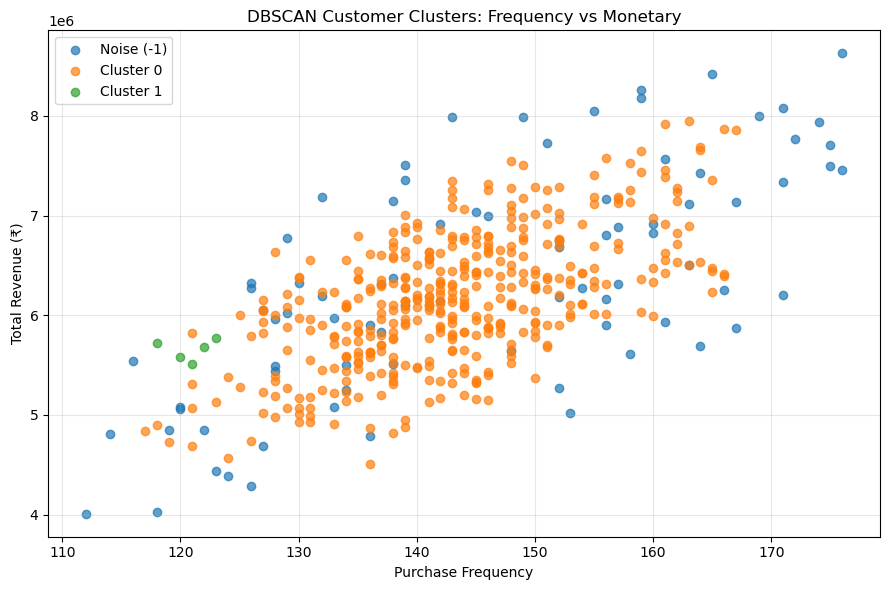

In [54]:

# Visualize DBSCAN Customer Clusters

import matplotlib.pyplot as plt

plt.figure(figsize=(9, 6))

for cluster_id in sorted(rfm["DBSCAN_Cluster"].unique()):
    cluster_data = rfm[rfm["DBSCAN_Cluster"] == cluster_id]

    label = "Noise (-1)" if cluster_id == -1 else f"Cluster {cluster_id}"

    plt.scatter(
        cluster_data["Frequency"],
        cluster_data["Monetary"],
        label=label,
        alpha=0.7
    )

plt.title("DBSCAN Customer Clusters: Frequency vs Monetary")
plt.xlabel("Purchase Frequency")
plt.ylabel("Total Revenue (₹)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


In [56]:

# Save DBSCAN Customer Segmentation Results

import os

os.makedirs("../data/processed", exist_ok=True)

rfm.to_csv(
    "../data/processed/customer_segments_dbscan.csv",
    index=False
)

print("DBSCAN results saved successfully!")
print("File: ../data/processed/customer_segments_dbscan.csv")
print("Dataset shape:", rfm.shape)
print("\nDBSCAN cluster distribution:")
print(rfm["DBSCAN_Cluster"].value_counts().sort_index())


DBSCAN results saved successfully!
File: ../data/processed/customer_segments_dbscan.csv
Dataset shape: (500, 7)

DBSCAN cluster distribution:
DBSCAN_Cluster
-1     83
 0    412
 1      5
Name: count, dtype: int64


In [58]:

# Compare K-Means and DBSCAN Results

kmeans_clusters = rfm["Cluster"].nunique()
dbscan_clusters = rfm.loc[
    rfm["DBSCAN_Cluster"] != -1,
    "DBSCAN_Cluster"
].nunique()

comparison = pd.DataFrame({
    "Metric": [
        "Total Customers",
        "K-Means Clusters",
        "DBSCAN Clusters (excluding noise)",
        "DBSCAN Noise Points",
        "DBSCAN Noise Percentage"
    ],
    "Value": [
        len(rfm),
        kmeans_clusters,
        dbscan_clusters,
        (rfm["DBSCAN_Cluster"] == -1).sum(),
        round((rfm["DBSCAN_Cluster"] == -1).mean() * 100, 2)
    ]
})

print(comparison.to_string(index=False))


                           Metric  Value
                  Total Customers  500.0
                 K-Means Clusters    4.0
DBSCAN Clusters (excluding noise)    2.0
              DBSCAN Noise Points   83.0
          DBSCAN Noise Percentage   16.6


In [60]:

# Validate K-Means Business Segment Names

segment_validation = rfm.groupby(["Cluster", "Segment_Name"]).agg(
    Customer_Count=("Customer_ID", "count"),
    Avg_Recency=("Recency", "mean"),
    Avg_Frequency=("Frequency", "mean"),
    Avg_Monetary=("Monetary", "mean")
).round(2)

print(segment_validation.to_string())


                                       Customer_Count  Avg_Recency  Avg_Frequency  Avg_Monetary
Cluster Segment_Name                                                                           
0       Recent Active Customers                   185         3.23         143.60    6276296.04
1       Lower Spending Customers                  137         4.48         131.44    5384576.54
2       High Value Frequent Customers              92         4.65         158.37    7181855.91
3       Needs Re-engagement                        86        12.92         145.56    6238653.61


In [62]:

# Compare K-Means Models with 4, 6, 7 and 8 Clusters

from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import pandas as pd

model_comparison = []
candidate_labels = {}

for k in [4, 6, 7, 8]:
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = model.fit_predict(rfm_scaled)
    candidate_labels[k] = labels

    cluster_sizes = pd.Series(labels).value_counts()

    model_comparison.append({
        "Clusters": k,
        "Inertia": round(model.inertia_, 2),
        "Silhouette_Score": round(
            silhouette_score(rfm_scaled, labels), 4
        ),
        "Smallest_Cluster": int(cluster_sizes.min()),
        "Largest_Cluster": int(cluster_sizes.max())
    })

model_comparison_df = pd.DataFrame(model_comparison)
print(model_comparison_df.to_string(index=False))


 Clusters  Inertia  Silhouette_Score  Smallest_Cluster  Largest_Cluster
        4   609.58            0.2761                86              185
        6   478.27            0.2865                16              171
        7   430.40            0.2618                16              143
        8   382.88            0.2625                19              108


In [64]:

# Inspect Customer Profiles for the 6-Cluster Candidate

rfm_6 = rfm[["Customer_ID", "Recency", "Frequency", "Monetary"]].copy()
rfm_6["Candidate_Cluster"] = candidate_labels[6]

profile_6 = rfm_6.groupby("Candidate_Cluster").agg(
    Customer_Count=("Customer_ID", "count"),
    Avg_Recency=("Recency", "mean"),
    Avg_Frequency=("Frequency", "mean"),
    Avg_Monetary=("Monetary", "mean")
).round(2)

profile_6["Customer_Percentage"] = (
    profile_6["Customer_Count"] / len(rfm_6) * 100
).round(2)

print(profile_6.to_string())


                   Customer_Count  Avg_Recency  Avg_Frequency  Avg_Monetary  Customer_Percentage
Candidate_Cluster                                                                               
0                             171         2.96         143.94    6299946.34                 34.2
1                              75         9.35         137.19    5718006.25                 15.0
2                              70         3.36         159.34    7236553.50                 14.0
3                              62        10.61         152.56    6745258.53                 12.4
4                              16        20.12         140.06    6120254.55                  3.2
5                             106         3.09         131.18    5351194.04                 21.2


In [66]:

# Assign Provisional Business Names to the 6-Cluster Candidate

candidate_names = {
    0: "Recently Active Customers",
    1: "At-Risk Moderate-Value Customers",
    2: "High-Value Frequent Customers",
    3: "At-Risk High-Value Customers",
    4: "High-Recency Customers",
    5: "Recent Lower-Spending Customers"
}

rfm_6["Candidate_Segment_Name"] = (
    rfm_6["Candidate_Cluster"].map(candidate_names)
)

candidate_profile = rfm_6.groupby(
    ["Candidate_Cluster", "Candidate_Segment_Name"]
).agg(
    Customer_Count=("Customer_ID", "count"),
    Avg_Recency=("Recency", "mean"),
    Avg_Frequency=("Frequency", "mean"),
    Avg_Monetary=("Monetary", "mean")
).round(2)

print(candidate_profile.to_string())


                                                    Customer_Count  Avg_Recency  Avg_Frequency  Avg_Monetary
Candidate_Cluster Candidate_Segment_Name                                                                    
0                 Recently Active Customers                    171         2.96         143.94    6299946.34
1                 At-Risk Moderate-Value Customers              75         9.35         137.19    5718006.25
2                 High-Value Frequent Customers                 70         3.36         159.34    7236553.50
3                 At-Risk High-Value Customers                  62        10.61         152.56    6745258.53
4                 High-Recency Customers                        16        20.12         140.06    6120254.55
5                 Recent Lower-Spending Customers              106         3.09         131.18    5351194.04


In [68]:

# Save the 6-Cluster Candidate Results

import os

os.makedirs("../data/processed", exist_ok=True)

rfm_6.to_csv(
    "../data/processed/customer_segments_kmeans6.csv",
    index=False
)

candidate_profile.to_csv(
    "../data/processed/customer_cluster_summary_kmeans6.csv"
)

print("6-cluster candidate saved successfully!")
print("Customer file shape:", rfm_6.shape)
print("Unique customers:", rfm_6["Customer_ID"].nunique())
print("Missing values:", rfm_6.isnull().sum().sum())
print("\nSegment counts:")
print(rfm_6["Candidate_Segment_Name"].value_counts())


6-cluster candidate saved successfully!
Customer file shape: (500, 6)
Unique customers: 500
Missing values: 0

Segment counts:
Candidate_Segment_Name
Recently Active Customers           171
Recent Lower-Spending Customers     106
At-Risk Moderate-Value Customers     75
High-Value Frequent Customers        70
At-Risk High-Value Customers         62
High-Recency Customers               16
Name: count, dtype: int64


In [70]:

# Verify Saved 6-Cluster Output Files

import os
import pandas as pd

customer_file = "../data/processed/customer_segments_kmeans6.csv"
summary_file = "../data/processed/customer_cluster_summary_kmeans6.csv"

print("Customer file exists:", os.path.exists(customer_file))
print("Summary file exists:", os.path.exists(summary_file))

saved_customers = pd.read_csv(customer_file)
saved_summary = pd.read_csv(summary_file)

print("\nCustomer file shape:", saved_customers.shape)
print("Unique customers:", saved_customers["Customer_ID"].nunique())
print("Missing values:", saved_customers.isnull().sum().sum())

print("\nSummary file shape:", saved_summary.shape)
print("\nSaved segment distribution:")
print(saved_customers["Candidate_Segment_Name"].value_counts())


Customer file exists: True
Summary file exists: True

Customer file shape: (500, 6)
Unique customers: 500
Missing values: 0

Summary file shape: (6, 6)

Saved segment distribution:
Candidate_Segment_Name
Recently Active Customers           171
Recent Lower-Spending Customers     106
At-Risk Moderate-Value Customers     75
High-Value Frequent Customers        70
At-Risk High-Value Customers         62
High-Recency Customers               16
Name: count, dtype: int64


In [72]:
# Compare 4-Cluster and 6-Cluster K-Means Models

comparison = pd.DataFrame({
    "Metric": [
        "Number of Clusters",
        "Silhouette Score",
        "Smallest Cluster",
        "Largest Cluster"
    ],
    "KMeans_4": [
        4,
        0.2761,
        86,
        185
    ],
    "KMeans_6": [
        6,
        0.2865,
        16,
        171
    ]
})

print(comparison.to_string(index=False))

            Metric  KMeans_4  KMeans_6
Number of Clusters    4.0000    6.0000
  Silhouette Score    0.2761    0.2865
  Smallest Cluster   86.0000   16.0000
   Largest Cluster  185.0000  171.0000


In [74]:
# Review the Smallest Cluster in the 6-Cluster Model

smallest_cluster = rfm_6[rfm_6["Candidate_Cluster"] == 4]

print("Number of Customers:", len(smallest_cluster))
print("\nRFM Profile:")
print(
    smallest_cluster[["Recency", "Frequency", "Monetary"]]
    .describe()
    .round(2)
)

Number of Customers: 16

RFM Profile:
       Recency  Frequency    Monetary
count    16.00      16.00       16.00
mean     20.12     140.06  6120254.55
std       4.88      10.24   387215.58
min      15.00     128.00  5505500.54
25%      16.50     133.75  5894830.65
50%      20.00     137.50  6122211.88
75%      22.25     142.00  6319768.80
max      33.00     167.00  6918710.11


In [76]:
# Compare Business Profiles of All 6 Customer Segments

segment_review = (
    rfm_6.groupby(["Candidate_Cluster", "Candidate_Segment_Name"])
    .agg(
        Customer_Count=("Customer_ID", "count"),
        Avg_Recency=("Recency", "mean"),
        Avg_Frequency=("Frequency", "mean"),
        Avg_Monetary=("Monetary", "mean")
    )
    .round(2)
    .reset_index()
)

print(segment_review.to_string(index=False))

 Candidate_Cluster           Candidate_Segment_Name  Customer_Count  Avg_Recency  Avg_Frequency  Avg_Monetary
                 0        Recently Active Customers             171         2.96         143.94    6299946.34
                 1 At-Risk Moderate-Value Customers              75         9.35         137.19    5718006.25
                 2    High-Value Frequent Customers              70         3.36         159.34    7236553.50
                 3     At-Risk High-Value Customers              62        10.61         152.56    6745258.53
                 4           High-Recency Customers              16        20.12         140.06    6120254.55
                 5  Recent Lower-Spending Customers             106         3.09         131.18    5351194.04


In [78]:
# Refine Segment Names Based on RFM Profiles

revised_names = {
    0: "Recently Active Customers",
    1: "Moderate-Value Re-engagement Candidates",
    2: "High-Value Frequent Customers",
    3: "High-Value Re-engagement Candidates",
    4: "High-Recency Re-engagement Candidates",
    5: "Recently Active Lower-Spending Customers"
}

rfm_6["Candidate_Segment_Name"] = (
    rfm_6["Candidate_Cluster"].map(revised_names)
)

print(
    rfm_6.groupby(
        ["Candidate_Cluster", "Candidate_Segment_Name"]
    ).size().to_string()
)

Candidate_Cluster  Candidate_Segment_Name                  
0                  Recently Active Customers                   171
1                  Moderate-Value Re-engagement Candidates      75
2                  High-Value Frequent Customers                70
3                  High-Value Re-engagement Candidates          62
4                  High-Recency Re-engagement Candidates        16
5                  Recently Active Lower-Spending Customers    106


In [80]:
# Save the Final Candidate Customer Segmentation Output

import os

output_path = "../data/processed/customer_segments_kmeans6.csv"

rfm_6.to_csv(output_path, index=False)

print("Saved file:", output_path)
print("Rows:", len(rfm_6))
print("Unique customers:", rfm_6["Customer_ID"].nunique())
print("Missing values:", rfm_6.isnull().sum().sum())
print("\nSegment counts:")
print(rfm_6["Candidate_Segment_Name"].value_counts())

Saved file: ../data/processed/customer_segments_kmeans6.csv
Rows: 500
Unique customers: 500
Missing values: 0

Segment counts:
Candidate_Segment_Name
Recently Active Customers                   171
Recently Active Lower-Spending Customers    106
Moderate-Value Re-engagement Candidates      75
High-Value Frequent Customers                70
High-Value Re-engagement Candidates          62
High-Recency Re-engagement Candidates        16
Name: count, dtype: int64


In [83]:
# Verify 6-Cluster Summary Against Saved Customer Segments

import pandas as pd

segments_path = "../data/processed/customer_segments_kmeans6.csv"
summary_path = "../data/processed/customer_cluster_summary_kmeans6.csv"

saved_segments = pd.read_csv(segments_path)
saved_summary = pd.read_csv(summary_path)

print("Saved Segments Shape:", saved_segments.shape)
print("Summary Shape:", saved_summary.shape)

print("\nCustomer count by cluster:")
print(
    saved_segments.groupby("Candidate_Cluster")["Customer_ID"]
    .nunique()
)

print("\nSaved summary columns:")
print(saved_summary.columns.tolist())

print("\nSaved 6-cluster summary:")
print(saved_summary.to_string(index=False))

Saved Segments Shape: (500, 6)
Summary Shape: (6, 6)

Customer count by cluster:
Candidate_Cluster
0    171
1     75
2     70
3     62
4     16
5    106
Name: Customer_ID, dtype: int64

Saved summary columns:
['Candidate_Cluster', 'Candidate_Segment_Name', 'Customer_Count', 'Avg_Recency', 'Avg_Frequency', 'Avg_Monetary']

Saved 6-cluster summary:
 Candidate_Cluster           Candidate_Segment_Name  Customer_Count  Avg_Recency  Avg_Frequency  Avg_Monetary
                 0        Recently Active Customers             171         2.96         143.94    6299946.34
                 1 At-Risk Moderate-Value Customers              75         9.35         137.19    5718006.25
                 2    High-Value Frequent Customers              70         3.36         159.34    7236553.50
                 3     At-Risk High-Value Customers              62        10.61         152.56    6745258.53
                 4           High-Recency Customers              16        20.12         140.06    61

In [85]:
# Synchronize the 6-Cluster Summary with Revised Segment Names

import pandas as pd

segments_path = "../data/processed/customer_segments_kmeans6.csv"
summary_path = "../data/processed/customer_cluster_summary_kmeans6.csv"

saved_segments = pd.read_csv(segments_path)
saved_summary = pd.read_csv(summary_path)

# Get the revised name for each cluster
name_mapping = (
    saved_segments[["Candidate_Cluster", "Candidate_Segment_Name"]]
    .drop_duplicates()
    .set_index("Candidate_Cluster")["Candidate_Segment_Name"]
)

# Update names while preserving the existing profile metrics
saved_summary["Candidate_Segment_Name"] = (
    saved_summary["Candidate_Cluster"].map(name_mapping)
)

saved_summary.to_csv(summary_path, index=False)

# Verify the saved summary
verified_summary = pd.read_csv(summary_path)

print("Summary saved and verified:")
print(verified_summary.to_string(index=False))

print("\nTotal customers in summary:", verified_summary["Customer_Count"].sum())
print("Number of clusters:", verified_summary["Candidate_Cluster"].nunique())
print("Missing values:", verified_summary.isnull().sum().sum())

Summary saved and verified:
 Candidate_Cluster                   Candidate_Segment_Name  Customer_Count  Avg_Recency  Avg_Frequency  Avg_Monetary
                 0                Recently Active Customers             171         2.96         143.94    6299946.34
                 1  Moderate-Value Re-engagement Candidates              75         9.35         137.19    5718006.25
                 2            High-Value Frequent Customers              70         3.36         159.34    7236553.50
                 3      High-Value Re-engagement Candidates              62        10.61         152.56    6745258.53
                 4    High-Recency Re-engagement Candidates              16        20.12         140.06    6120254.55
                 5 Recently Active Lower-Spending Customers             106         3.09         131.18    5351194.04

Total customers in summary: 500
Number of clusters: 6
Missing values: 0


## Final Customer Segmentation — Model Selection and Results

### Objective
The objective was to group customers using Recency, Frequency, and Monetary (RFM) features to support customer analytics and targeted engagement strategies.

### Model Comparison
Two K-Means configurations were compared:

- **4 clusters:** Silhouette Score = 0.2761; cluster sizes range from 86 to 185.
- **6 clusters:** Silhouette Score = 0.2865; cluster sizes range from 16 to 171.

The 6-cluster model was selected as the preferred candidate because it provides six interpretable customer groups and a slightly higher Silhouette Score. The improvement is modest, so the result should not be interpreted as proof of strong cluster separation.

### Final Candidate Segments

| Segment | Customers |
|---|---:|
| Recently Active Customers | 171 |
| Recently Active Lower-Spending Customers | 106 |
| Moderate-Value Re-engagement Candidates | 75 |
| High-Value Frequent Customers | 70 |
| High-Value Re-engagement Candidates | 62 |
| High-Recency Re-engagement Candidates | 16 |
| **Total** | **500** |

### DBSCAN Experiment
DBSCAN was also evaluated. The tested configuration produced a dominant cluster and 83 noise points, so it was not selected as the primary segmentation candidate.

### Output Files
- `customer_segments.csv` — original 4-cluster K-Means output.
- `customer_cluster_summary.csv` — original 4-cluster summary.
- `customer_segments_dbscan.csv` — DBSCAN results.
- `customer_segments_kmeans6.csv` — revised 6-cluster candidate output.
- `customer_cluster_summary_kmeans6.csv` — 6-cluster profile summary.

### Limitations
The Silhouette Scores indicate only modest separation between clusters. The smallest cluster contains 16 customers and should be interpreted cautiously. Customer transaction assignments are modelled/generated rather than verified individual-level purchase histories. Segment labels are exploratory business interpretations, not confirmed churn predictions. Further validation with genuine customer-level data is recommended.
